# IRRBB: EVE & NII Under Basel Shock Scenarios

A bank's exposure to interest rates shows up in two ways that usually pull against each other: the value of its balance sheet and the income it earns over the next year. For a development bank the key choice is how to invest its own equity, and that choice moves one measure at the expense of the other. This notebook measures both under the Basel shocks and maps the trade-off.

**What it does.** It measures the interest-rate risk in the banking book of a stylised multilateral development bank: a $4bn liquidity portfolio built from real bonds and 80% asset-swapped to SOFR, a $12bn SOFR loan book, $14bn of fixed-rate bonds swapped to floating, and $6bn of equity.

It computes the change in economic value of equity (ΔEVE) under the six Basel IRRBB shocks and the 12-month change in net interest income (ΔNII), and runs 1-year historical curve scenarios.

The risk is then split into level, slope and curvature, and the notebook maps the trade-off between EVE and NII that an MDB's equity-duration policy has to settle.

**Data.** Bond-level holdings of four iShares ETFs for the liquidity portfolio, today's Treasury par curve (U.S. Treasury), ten years of daily Treasury yields (FRED) and an explicit SOFR–Treasury swap-spread assumption.

**Methods.** Cash-flow generation for fixed, floating, amortising and swapped instruments, full revaluation on shocked SOFR curves (BCBS 368 standardised shocks with the zero floor), repricing-gap ΔNII and overlapping 1-year historical curve changes.

PCA factors and an OLS regression of ΔEVE on them explain the risk, and an efficient frontier compares equity-duration strategies.

**Key output.** ΔEVE by scenario and the Basel outlier test (15% of Tier 1), ΔNII under ±200 bp, the distribution of 1-year ΔEVE and EVE-at-risk, factor sensitivities, and the EVE–NII frontier with today's position on it.

## 1. IRRBB for an MDB

Interest-rate risk in the banking book (IRRBB) is measured from two angles that usually pull in opposite directions:

- **Economic value of equity (EVE):** the present value of assets minus liabilities. Long fixed-rate positions make EVE fall when rates rise.
- **Net interest income (NII):** the income of the next 12 months. Floating positions make NII fall when rates fall.

An MDB has no deposits, and its balance sheet is simpler than a commercial bank's: it lends mostly at floating SOFR spreads, issues fixed-rate bonds that it swaps to floating, and holds a liquidity portfolio. The real decision is **how to invest its equity**. Equity has no maturity, so it can be left floating (NII swings with SOFR, EVE is stable) or invested in a ladder of fixed-rate assets or receive-fixed swaps (NII is stable, EVE moves with rates).

Many MDBs follow an explicit **equity duration** target for this reason. The notebook measures both sides and shows the frontier.

The Basel standard (BCBS 368, 2016) prescribes six shocks for USD: parallel ±200 bp, short-rate ±300 bp, and steepener and flattener rotations built from a 300 bp short shock and a 150 bp long shock. A bank is an **outlier** if its worst ΔEVE exceeds 15% of Tier 1 capital.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
from scipy.optimize import brentq
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# --- Liquidity portfolio (MDB-style sleeves, scaled to $4bn)
PORTFOLIO_SIZE_USD = 4_000_000_000
SLEEVE_TARGETS = {
    "US Treasuries": 0.40,
    "Agencies": 0.20,
    "Sub-sovereigns": 0.10,
    "Banks": 0.15,
    "Corporates": 0.15,
}
BONDS_PER_SLEEVE = 30
MATURITY_RANGE_Y = (1.0, 30.0)
KEY_TENORS = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])

# --- Stylised MDB balance sheet ($bn)
LOANS_BN, BORROWINGS_BN, EQUITY_BN = 12.0, 14.0, 6.0
# share of loans at fixed rates (the rest pay SOFR + spread, quarterly reset)
FIXED_LOAN_SHARE = 0.20
# share of each liquidity-portfolio bond swapped to SOFR (pay the coupon,
# receive SOFR)
ASSET_SWAP_SHARE = 0.80
# base policy: equity invested in an equal-weight receive-fixed swap ladder of
# 1..5 years
EQUITY_LADDER_YEARS = 5
N_LOANS, N_BONDS = 400, 40
# BCBS 368 Annex 2 shock sizes for USD (bp)
BASEL_USD = {"parallel": 200, "short": 300, "long": 150}
SEED = 13

print(f"QuantLib {ql.__version__} · run on {dt.date.today():%Y-%m-%d}")

QuantLib 1.44 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


SCEN_ORDER = [
    "Parallel up",
    "Parallel down",
    "Steepener",
    "Flattener",
    "Short rates up",
    "Short rates down",
]
SCEN_COLORS = dict(
    zip(
        SCEN_ORDER,
        [
            PALETTE[7],
            PALETTE[0],
            PALETTE[3],
            PALETTE[6],
            PALETTE[1],
            PALETTE[2],
        ],
    )
)

## 3. Data: the liquidity portfolio and today's curves

The liquidity portfolio is built from real bonds in iShares holdings files, scaled to $4bn:

| Sleeve | ETF | Product id |
|---|---|---|
| US Treasuries | GOVT | 239468 |
| Agencies | AGZ | 239457 |
| Sub-sovereigns | MUB (US states and municipalities) | 239766 |
| Banks / Corporates | IGIB (split by sector) | 239463 |

In [3]:
ISHARES_FUNDS = {
    "GOVT": "239468",
    "AGZ": "239457",
    "MUB": "239766",
    "IGIB": "239463",
}
SLEEVE_BY_FUND = {
    "GOVT": "US Treasuries",
    "AGZ": "Agencies",
    "MUB": "Sub-sovereigns",
}


def fetch_holdings(ticker: str) -> pd.DataFrame:
    """
    Download one iShares fund's holdings file and return the holdings table as
    text columns.
    """
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=30
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    table = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    table["fund"], table["as_of"] = ticker, as_of
    return table


raw_holdings = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)


def to_number(s):
    """'1,234.50' -> 1234.5 ; '-' or '' -> NaN."""
    return pd.to_numeric(
        s.astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )


col = lambda name, default="": (
    raw_holdings[name]
    if name in raw_holdings
    else pd.Series(default, index=raw_holdings.index)
)
bonds = pd.DataFrame({
    "fund": raw_holdings["fund"],
    "name": raw_holdings["Name"],
    "sector": col("Sector").fillna(""),
    "asset_class": col("Asset Class").fillna(""),
    "currency": col("Currency", "USD").fillna(""),
    "isin": col("ISIN"),
    "weight_pct": to_number(raw_holdings["Weight (%)"]),
    "clean_price": to_number(col("Price", np.nan)),
    "coupon_pct": to_number(raw_holdings["Coupon (%)"]),
    "ishares_duration": to_number(col("Duration", np.nan)),
    "ishares_ytm_pct": to_number(col("YTM (%)", np.nan)),
    "maturity": pd.to_datetime(
        raw_holdings["Maturity"], format="%b %d, %Y", errors="coerce"
    ).fillna(
        pd.to_datetime(
            raw_holdings["Maturity"], format="mixed", errors="coerce"
        )
    ),
    "as_of": raw_holdings["as_of"],
})
# Sleeve = the fund it came from; the corporate fund is split into banks and
# other corporates by sector
bonds["sleeve"] = [
    SLEEVE_BY_FUND.get(f)
    or ("Banks" if re.search("bank", s, re.I) else "Corporates")
    for f, s in zip(bonds["fund"], bonds["sector"])
]


def clean_price_from_ytm(coupon_pct, ytm_pct, maturity, settle):
    """
    Clean price per 100 from a semi-annual yield, used when a holdings file has
    no Price column.
    """
    if (
        any(pd.isna(v) for v in (coupon_pct, ytm_pct, maturity, settle))
        or maturity <= settle
    ):
        return np.nan
    c, y = coupon_pct / 2, ytm_pct / 200
    # coupon dates, walking back from maturity
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfs = dates[-1], sorted(dates[:-1])
    # fraction of the first period still to run
    frac = (cfs[0] - settle).days / (cfs[0] - prev).days
    dirty = sum(c / (1 + y) ** (frac + k) for k in range(len(cfs))) + 100 / (
        1 + y
    ) ** (frac + len(cfs) - 1)
    # remove accrued interest
    return dirty - c * (1 - frac)


missing_price = bonds["clean_price"].isna() & bonds["ishares_ytm_pct"].notna()
settle = pd.to_datetime(bonds["as_of"], format="%b %d, %Y", errors="coerce")
bonds.loc[missing_price, "clean_price"] = [
    clean_price_from_ytm(c, y, m, s)
    for c, y, m, s in zip(
        bonds.loc[missing_price, "coupon_pct"],
        bonds.loc[missing_price, "ishares_ytm_pct"],
        bonds.loc[missing_price, "maturity"],
        settle[missing_price],
    )
]
if missing_price.any():
    print(
        "Clean price rebuilt from iShares YTM for"
        f" {missing_price.sum()} holdings"
        f" ({', '.join(bonds.loc[missing_price, 'fund'].unique())}: file has"
        " no Price column)"
    )
print(
    f"{len(bonds):,} holdings parsed · "
    + ", ".join(f"{f} {n:,}" for f, n in bonds["fund"].value_counts().items())
)

Clean price rebuilt from iShares YTM for 119 holdings (AGZ: file has no Price column)
11,007 holdings parsed · MUB 7,604, IGIB 3,053, GOVT 231, AGZ 119


In [4]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    """
    Daily Treasury par yield curves for the current year (falls back to last
    year in early January).
    """
    get = lambda year: pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    raw = get(dt.date.today().year)
    if len(raw) < 20:  # early January: add last year's file
        raw = pd.concat(
            [raw, get(dt.date.today().year - 1)], ignore_index=True
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

FRED_KEY_SERIES = {
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_history():
    frames = []
    for sid, tenor in FRED_KEY_SERIES.items():
        s = fred.get_series(
            sid, observation_start=EVAL_DATE - pd.Timedelta(days=3653)
        ).dropna()
        frames.append(
            pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        )
    return pd.concat(frames, ignore_index=True)


history = (
    cached("fred_treasury_key_rates", fetch_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()[list(KEY_TENORS)]
    .dropna()
)
daily_changes_bp = history.diff().dropna() * 100
print(
    f"Evaluation date {EVAL_DATE:%Y-%m-%d} · {len(daily_changes_bp):,} daily"
    f" curve moves ({daily_changes_bp.index.min():%Y} →"
    f" {daily_changes_bp.index.max():%Y})"
)

Evaluation date 2026-10-19 · 2,498 daily curve moves (2016 → 2026)


In [5]:
today = EVAL_DATE.normalize()
bonds["years_to_maturity"] = (bonds["maturity"] - today).dt.days / 365.25
eligible = bonds[
    bonds["currency"].eq("USD")
    & bonds["clean_price"].gt(0)
    & bonds["coupon_pct"].notna()
    & bonds["years_to_maturity"].between(*MATURITY_RANGE_Y)
    & ~bonds["asset_class"].str.contains(
        "Cash|Money Market|Futures", case=False
    )
    & bonds["sleeve"].isin(SLEEVE_TARGETS)
].copy()

# The largest holdings of each sleeve, re-weighted to the sleeve's target share
# of the portfolio
portfolio = (
    eligible.sort_values("weight_pct", ascending=False)
    .groupby("sleeve", group_keys=False)
    .head(BONDS_PER_SLEEVE)
    .copy()
)
portfolio["market_value"] = (
    portfolio.groupby("sleeve")["weight_pct"].transform(lambda w: w / w.sum())
    * portfolio["sleeve"].map(SLEEVE_TARGETS)
    * PORTFOLIO_SIZE_USD
)
portfolio = portfolio.reset_index(drop=True)
SLEEVE_COLORS = dict(zip(SLEEVE_TARGETS, PALETTE))

portfolio.groupby("sleeve").agg(
    bonds=("name", "size"),
    market_value_mm=("market_value", lambda v: v.sum() / 1e6),
    avg_coupon_pct=("coupon_pct", "mean"),
    avg_maturity_y=("years_to_maturity", "mean"),
).reindex(SLEEVE_TARGETS)

,bonds,market_value_mm,avg_coupon_pct,avg_maturity_y
sleeve,,,,
US Treasuries,30,"1,600.00",3.28,6.53
Agencies,30,800.00,4.43,4.09
Sub-sovereigns,30,400.00,4.93,16.46
Banks,30,600.00,5.22,8.50
Corporates,30,600.00,4.88,8.15


In [6]:
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)


def build_treasury_curve(par_row):
    """
    Bootstrap a Treasury zero curve from one day's par yields (bills as zeros,
    notes/bonds at par).
    """
    helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
    for tenor, par_yield in par_row.items():
        y = par_yield / 100
        period = (
            ql.Period(int(round(tenor * 52)), ql.Weeks)
            if tenor < 1
            else ql.Period(int(round(tenor * 12)), ql.Months)
        )
        maturity = US_GOVT.advance(ql_today, period)
        freq, coupons, price = (
            (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
            if tenor <= 1
            else (ql.Semiannual, [y], 100.0)
        )
        schedule = ql.Schedule(
            ql_today,
            maturity,
            ql.Period(freq),
            US_GOVT,
            ql.Unadjusted,
            ql.Unadjusted,
            ql.DateGeneration.Backward,
            False,
        )
        helpers.append(
            ql.FixedRateBondHelper(
                ql.QuoteHandle(ql.SimpleQuote(price)),
                0,
                100.0,
                schedule,
                coupons,
                bond_dc,
            )
        )
    curve = ql.PiecewiseConvexMonotoneForward(
        ql_today, helpers, ql.Actual365Fixed()
    )
    curve.enableExtrapolation()
    return curve


ust_curve = build_treasury_curve(par_today)
GRID_T = np.linspace(1 / 365, 31, 31 * 52)
# continuous zero rates
GRID_Z = np.array(
    [ust_curve.zeroRate(float(t), ql.Continuous).rate() for t in GRID_T]
)


def zero_rate(t):
    """
    Treasury zero rate (decimal, continuous) at times t (years), by
    interpolation on the grid.
    """
    return np.interp(t, GRID_T, GRID_Z)


def cash_flows(coupon_pct, years_to_maturity):
    """
    Times (years) and amounts per 100 face of a semi-annual fixed-coupon bond.
    """
    times = np.arange(years_to_maturity, 0, -0.5)[::-1]
    amounts = np.full(len(times), coupon_pct / 2)
    amounts[-1] += 100
    return times, amounts


def price_from_curve(times, amounts, spread, shift=None, zero=None):
    """
    Dirty price per 100 face on a zero curve + constant spread (+ an optional
    bump function of t).
    """
    z = (
        (zero_rate(times) if zero is None else zero(times))
        + spread
        + (0 if shift is None else shift(times))
    )
    return float(np.sum(amounts * np.exp(-z * times)))


records = []
for i, b in portfolio.iterrows():
    times, amounts = cash_flows(b["coupon_pct"], b["years_to_maturity"])
    # linear accrual since the last coupon
    accrued = b["coupon_pct"] / 2 * (1 - times[0] / 0.5)
    dirty = b["clean_price"] + accrued
    try:
        z_spread = brentq(
            lambda s: price_from_curve(times, amounts, s) - dirty, -0.05, 0.20
        )
    # price outside any reasonable spread (bad print): dropped below
    except ValueError:
        z_spread = np.nan
    records.append({
        "times": times,
        "amounts": amounts,
        "accrued": accrued,
        "dirty_price": dirty,
        "z_spread_bp": z_spread * 1e4,
    })

portfolio = pd.concat([portfolio, pd.DataFrame(records)], axis=1)
dropped = portfolio["z_spread_bp"].isna().sum()
portfolio = portfolio.dropna(subset=["z_spread_bp"]).reset_index(drop=True)
# USD face amount held
portfolio["face"] = portfolio["market_value"] / portfolio["dirty_price"] * 100
print(
    f"Treasury zero curve: "
    + ", ".join(
        f"{tenor_label(t)} {zero_rate(t)*100:.2f}%"
        for t in (0.5, 2, 5, 10, 30)
    )
    + (
        f" · {dropped} bond(s) dropped (price inconsistent with any spread)"
        if dropped
        else ""
    )
)

Treasury zero curve: 6M 4.34%, 2Y 4.71%, 5Y 4.89%, 10Y 5.12%, 30Y 5.45%


In [7]:
# SOFR OIS minus Treasury (bp): an explicit, documented swap-spread assumption
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}
spread_t, spread_v = (
    np.array(list(SWAP_SPREAD_BP)),
    np.array(list(SWAP_SPREAD_BP.values())) / 1e4,
)


def sofr_zero(t, ust_zero=None):
    """SOFR zero rate = Treasury zero + swap spread (decimal, continuous)."""
    base = zero_rate(t) if ust_zero is None else ust_zero(t)
    return base + np.interp(t, spread_t, spread_v)

## 4. The balance sheet as cash flows

Every position is reduced to dated cash flows, generated from a curve so that floating legs re-project their coupons when the curve is shocked:

| Position | Size | Cash flows |
|---|---|---|
| Liquidity portfolio | $4bn | the real bonds' fixed coupons and principal |
| Asset swaps | 80% of the portfolio's face | pay each bond's coupon, receive SOFR quarterly: the standard MDB practice of holding liquidity at floating rates |
| Floating loans | 80% of $12bn | quarterly SOFR forward + spread (100–250 bp), amortising, 3–15 years |
| Fixed loans | 20% of $12bn | quarterly fixed coupon (SOFR swap rate + spread at origination), amortising |
| Bonds issued | $14bn | semi-annual fixed coupons, 1–10-year bullets |
| Liability swaps | $14bn notional | receive the bond coupon, pay SOFR quarterly: funding becomes floating |
| Equity | $6bn | no cash flows; invested through a **receive-fixed swap ladder** of 1 to 5 years |

All cash flows are discounted on the SOFR zero curve, so credit spreads are held constant, as Basel IRRBB requires. Positions start mid-life, with maturities and coupons drawn from realistic ranges (seeded).

In [8]:
rng = np.random.default_rng(SEED)
Q = 0.25


def fwd_rates(zero_fn, t0, t1):
    """Simple forward rate between t0 and t1 from a continuous zero curve."""
    df0, df1 = np.exp(-zero_fn(t0) * t0), np.exp(-zero_fn(t1) * t1)
    return (df0 / df1 - 1) / (t1 - t0)


def par_swap_rate(zero_fn, years, freq=0.25):
    t = np.arange(freq, years + 1e-9, freq)
    df = np.exp(-zero_fn(t) * t)
    return (1 - df[-1]) / (freq * df.sum())


def instrument_cashflows(ins, zero_fn, base_zero_fn=None):
    """
    Times and amounts ($bn) of one instrument; floating coupons are projected
    from zero_fn after the first reset.
    """
    base_zero_fn = base_zero_fn or zero_fn
    kind = ins["kind"]
    # real portfolio bond, fixed coupons
    if kind == "bond":
        return ins["times"], ins["amounts"] * ins["face"] / 100 / 1e9
    t = np.arange(ins["first"], ins["maturity"] + 1e-9, ins["freq"])
    if len(t) == 0:
        return np.array([]), np.array([])
    n = len(t)
    if ins["amortising"]:
        principal = np.full(n, ins["notional"] / n)
    else:
        principal = np.zeros(n)
        principal[-1] = ins["notional"]
    outstanding = ins["notional"] - np.r_[0, np.cumsum(principal)[:-1]]
    if ins["rate_type"] == "fixed":
        rate = np.full(n, ins["rate"])
    else:
        starts = np.maximum(t - ins["freq"], 0)
        rate = fwd_rates(zero_fn, np.maximum(starts, 1e-6), t) + ins["spread"]
        # the first coupon is already fixed
        rate[0] = ins["current_coupon"]
    interest = outstanding * rate * ins["freq"]
    sign = ins["sign"]
    return t, sign * (
        interest + (principal if ins["exchange_principal"] else 0)
    )


def build_book(zero_fn):
    book = []
    for _, b in portfolio.iterrows():
        book.append({
            "name": b["name"],
            "group": "Liquidity portfolio",
            "kind": "bond",
            "times": b["times"],
            "amounts": b["amounts"],
            "face": b["face"],
            "reprice": b["years_to_maturity"],
            "notional": b["market_value"] / 1e9,
            "rate_type": "fixed",
            "coupon_rate": b["coupon_pct"] / 100,
            "sign": 1,
        })
        # asset swap: pay the bond's fixed coupons, receive SOFR, on
        # ASSET_SWAP_SHARE of the face amount
        n_sw = ASSET_SWAP_SHARE * b["face"] / 1e9
        mat = b["years_to_maturity"]
        fix = {
            "name": f"ASW fixed {b['name']}",
            "group": "Asset swaps",
            "kind": "swap",
            "first": float(b["times"][0]),
            "maturity": mat,
            "freq": 0.5,
            "amortising": False,
            "notional": n_sw,
            "exchange_principal": False,
            "sign": -1,
            "rate_type": "fixed",
            "rate": b["coupon_pct"] / 100,
            "reprice": mat,
            "coupon_rate": b["coupon_pct"] / 100,
        }
        fl = {
            "name": f"ASW float {b['name']}",
            "group": "Asset swaps",
            "kind": "swap",
            "first": float(rng.uniform(0.01, Q)),
            "maturity": mat,
            "freq": Q,
            "amortising": False,
            "notional": n_sw,
            "exchange_principal": False,
            "sign": 1,
            "rate_type": "floating",
            "spread": 0.0,
        }
        fl["current_coupon"] = float(fwd_rates(zero_fn, 1e-6, fl["first"]))
        fl["reprice"], fl["coupon_rate"] = fl["first"], fl["current_coupon"]
        book += [fix, fl]
    loan_sizes = rng.dirichlet(np.ones(N_LOANS)) * LOANS_BN
    for i in range(N_LOANS):
        mat = rng.uniform(3, 15)
        first = rng.uniform(0.01, Q)
        fixed = rng.random() < FIXED_LOAN_SHARE
        spread = rng.uniform(0.010, 0.025)
        ins = {
            "name": f"Loan {i}",
            "group": "Loans (fixed)" if fixed else "Loans (floating)",
            "kind": "loan",
            "first": first,
            "maturity": mat,
            "freq": Q,
            "amortising": True,
            "notional": loan_sizes[i],
            "exchange_principal": True,
            "sign": 1,
            "rate_type": "fixed" if fixed else "floating",
            "spread": spread,
            "current_coupon": float(fwd_rates(zero_fn, 1e-6, first) + spread),
        }
        ins["rate"] = par_swap_rate(zero_fn, mat) + spread if fixed else None
        ins["reprice"] = mat if fixed else first
        ins["coupon_rate"] = ins["rate"] if fixed else ins["current_coupon"]
        book.append(ins)
    bond_sizes = rng.dirichlet(np.ones(N_BONDS) * 2) * BORROWINGS_BN
    for i in range(N_BONDS):
        mat = rng.uniform(1, 10)
        first = mat % 0.5 or 0.5
        # MDB funding near SOFR swaps
        cpn = par_swap_rate(zero_fn, mat, 0.5) + rng.uniform(-0.001, 0.002)
        bond = {
            "name": f"Bond {i}",
            "group": "Bonds issued",
            "kind": "debt",
            "first": first,
            "maturity": mat,
            "freq": 0.5,
            "amortising": False,
            "notional": bond_sizes[i],
            "exchange_principal": True,
            "sign": -1,
            "rate_type": "fixed",
            "rate": cpn,
            "reprice": mat,
            "coupon_rate": cpn,
        }
        rec_fixed = {
            **bond,
            "name": f"Swap {i} fixed leg",
            "group": "Liability swaps",
            "kind": "swap",
            "exchange_principal": False,
            "sign": 1,
        }
        pay_float = {
            "name": f"Swap {i} float leg",
            "group": "Liability swaps",
            "kind": "swap",
            "first": rng.uniform(0.01, Q),
            "maturity": mat,
            "freq": Q,
            "amortising": False,
            "notional": bond_sizes[i],
            "exchange_principal": False,
            "sign": -1,
            "rate_type": "floating",
            "spread": 0.0,
        }
        pay_float["current_coupon"] = float(
            fwd_rates(zero_fn, 1e-6, pay_float["first"])
        )
        pay_float["reprice"], pay_float["coupon_rate"] = (
            pay_float["first"],
            pay_float["current_coupon"],
        )
        book += [bond, rec_fixed, pay_float]
    return book


def equity_ladder(zero_fn, years):
    """
    Receive-fixed / pay-SOFR swaps of 1..years, equal notional, totalling
    EQUITY_BN (empty if years == 0).
    """
    legs = []
    for y in range(1, years + 1):
        n = EQUITY_BN / years
        k = par_swap_rate(zero_fn, y)
        legs.append({
            "name": f"Equity swap {y}y fixed",
            "group": "Equity ladder swaps",
            "kind": "swap",
            "first": Q,
            "maturity": y,
            "freq": Q,
            "amortising": False,
            "notional": n,
            "exchange_principal": False,
            "sign": 1,
            "rate_type": "fixed",
            "rate": k,
            "reprice": y,
            "coupon_rate": k,
        })
        fl = {
            "name": f"Equity swap {y}y float",
            "group": "Equity ladder swaps",
            "kind": "swap",
            "first": Q,
            "maturity": y,
            "freq": Q,
            "amortising": False,
            "notional": n,
            "exchange_principal": False,
            "sign": -1,
            "rate_type": "floating",
            "spread": 0.0,
            "current_coupon": float(fwd_rates(zero_fn, 1e-6, Q)),
        }
        fl["reprice"], fl["coupon_rate"] = Q, fl["current_coupon"]
        legs.append(fl)
    return legs


base_curve = lambda t: sofr_zero(np.asarray(t, dtype=float))
book = build_book(base_curve)
ladder = equity_ladder(base_curve, EQUITY_LADDER_YEARS)


def pv(instruments, zero_fn):
    out = {}
    for ins in instruments:
        t, a = instrument_cashflows(ins, zero_fn)
        out[ins["group"]] = (
            out.get(ins["group"], 0.0)
            + float(np.sum(a * np.exp(-zero_fn(t) * t)))
            if len(t)
            else out.get(ins["group"], 0.0)
        )
    return pd.Series(out)


pv0 = pv(book + ladder, base_curve)
# cash (overnight) that balances the sheet: assets − liabilities = equity
cash_plug = EQUITY_BN - pv0.sum()
print(
    f"{len(book) + len(ladder)} cash-flow instruments · SOFR 1y"
    f" {base_curve(1) * 100:.2f}%, 5y {base_curve(5) * 100:.2f}%, 10y"
    f" {base_curve(10) * 100:.2f}% · overnight cash balancing item"
    f" ${cash_plug:.2f}bn"
)
pv0.to_frame("PV ($bn)").round(3).reindex([
    "Liquidity portfolio",
    "Asset swaps",
    "Loans (floating)",
    "Loans (fixed)",
    "Bonds issued",
    "Liability swaps",
    "Equity ladder swaps",
])

980 cash-flow instruments · SOFR 1y 4.30%, 5y 4.64%, 10y 4.72% · overnight cash balancing item $2.89bn


,PV ($bn)
Liquidity portfolio,4.14
Asset swaps,0.08
Loans (floating),10.09
Loans (fixed),2.79
Bonds issued,-14.15
Liability swaps,0.16
Equity ladder swaps,0.00


## 5. ΔEVE under the six Basel shocks

With $S_\text{short}=300$, $S_\text{long}=150$ and $S_\text{parallel}=200$ bp for USD, the shocks to the zero curve at maturity $t$ are (BCBS 368, Annex 2):

$$
\Delta_\text{short}(t)=S_\text{short}\,e^{-t/4},\qquad \Delta_\text{long}(t)=S_\text{long}\,(1-e^{-t/4}),
$$
$$
\text{steepener}=-0.65\,|\Delta_\text{short}|+0.9\,|\Delta_\text{long}|,\qquad \text{flattener}=+0.8\,|\Delta_\text{short}|-0.6\,|\Delta_\text{long}|.
$$

Shocked rates are floored at zero. ΔEVE is the change in PV of all positions plus the overnight cash, which does not move; the outlier test compares the worst ΔEVE with 15% of Tier 1, here equity.

In [9]:
def shock_fn(name):
    S, L, P = (
        BASEL_USD["short"] / 1e4,
        BASEL_USD["long"] / 1e4,
        BASEL_USD["parallel"] / 1e4,
    )
    short = lambda t: S * np.exp(-t / 4)
    long_ = lambda t: L * (1 - np.exp(-t / 4))
    return {
        "Parallel up": lambda t: P + 0 * t,
        "Parallel down": lambda t: -P + 0 * t,
        "Steepener": lambda t: -0.65 * short(t) + 0.9 * long_(t),
        "Flattener": lambda t: 0.8 * short(t) - 0.6 * long_(t),
        "Short rates up": short,
        "Short rates down": lambda t: -short(t),
    }[name]


def shocked(shift):
    return lambda t: np.maximum(
        base_curve(t) + shift(np.asarray(t, dtype=float)), 0.0
    )


def eve_change(shift, instruments):
    return pv(instruments, shocked(shift)) - pv(instruments, base_curve)


eve_rows = {s: eve_change(shock_fn(s), book + ladder) for s in SCEN_ORDER}
eve = pd.DataFrame(eve_rows).T.fillna(0)
eve["ΔEVE ($bn)"] = eve.sum(axis=1)
eve["ΔEVE % of equity"] = eve["ΔEVE ($bn)"] / EQUITY_BN * 100
worst = eve["ΔEVE ($bn)"].idxmin()
print(
    f"Worst Basel scenario: {worst} · ΔEVE"
    f" {eve.loc[worst, 'ΔEVE ($bn)'] * 1e3:,.0f}mm ="
    f" {eve.loc[worst, 'ΔEVE % of equity']:.1f}% of equity "
    f"→ {'OUTLIER (>15%)' if eve.loc[worst, 'ΔEVE % of equity'] < -15 else 'within the 15% outlier threshold'}"
)
(eve * 1e3).round(0).drop(columns="ΔEVE % of equity").join(
    eve["ΔEVE % of equity"].round(2)
)

Worst Basel scenario: Parallel up · ΔEVE -591mm = -9.8% of equity → within the 15% outlier threshold


,Liquidity portfolio,Asset swaps,Loans (floating),Loans (fixed),Bonds issued,Liability swaps,Equity ladder swaps,ΔEVE ($bn),ΔEVE % of equity
Parallel up,-441.00,339.00,-62.00,-195.00,"1,265.00","-1,204.00",-292.00,-591.00,-9.84
Parallel down,540.00,-417.00,67.00,221.00,"-1,433.00","1,368.00",315.00,660.00,11.00
Steepener,-165.00,138.00,19.00,-39.00,332.00,-355.00,-10.00,-79.00,-1.31
Flattener,77.00,-71.00,-32.00,-5.00,-48.00,83.00,-57.00,-53.00,-0.88
Short rates up,-133.00,92.00,-56.00,-89.00,502.00,-444.00,-173.00,-299.00,-4.99
Short rates down,138.00,-96.00,57.00,92.00,-521.00,462.00,181.00,312.00,5.21


## 6. ΔNII over 12 months

NII is measured on a constant balance sheet: every position that matures or reprices within the year is replaced by the same position at the shocked rate. A position contributes $\pm N\,\Delta r\,(1-t_\text{reprice})$ if it reprices at $t_\text{reprice}<1$ year. Floating loans, the pay-SOFR legs of the swaps and the overnight cash reprice within a quarter; fixed bonds and the receive-fixed legs only when they mature. Base NII is the current-coupon income on the same book.

In [10]:
def nii_parts(instruments, dr, cash=cash_plug, horizon=1.0):
    """
    Base annual NII and the average annual ΔNII over `horizon` years for an
    instantaneous parallel shock dr.
    """
    base, delta = {}, {}
    for ins in instruments:
        g, n, s = ins["group"], ins["notional"], ins["sign"]
        cpn = (
            ins["coupon_rate"] if ins["kind"] != "bond" else ins["coupon_rate"]
        )
        base[g] = base.get(g, 0.0) + s * n * cpn
        tr = ins["reprice"]
        if tr < horizon:
            delta[g] = (
                delta.get(g, 0.0) + s * n * dr * (horizon - tr) / horizon
            )
    base["Overnight cash"] = cash * float(base_curve(1 / 365))
    delta["Overnight cash"] = cash * dr
    return pd.Series(base), pd.Series(delta)


nii_base, _ = nii_parts(book + ladder, 0.0)
nii_tab = pd.DataFrame({
    f"ΔNII {lbl} ($mm)": nii_parts(book + ladder, dr)[1] * 1e3
    for lbl, dr in [("+200bp", 0.02), ("−200bp", -0.02)]
})
nii_tab.loc["Total"] = nii_tab.sum()
NII0 = nii_base.sum()
print(
    f"Base 12-month NII ${NII0 * 1e3:,.0f}mm · ΔNII +200bp"
    f" ${nii_tab.loc['Total', 'ΔNII +200bp ($mm)']:,.0f}mm"
    f" ({nii_tab.loc['Total', 'ΔNII +200bp ($mm)'] / (NII0 * 1e3) * 100:+.0f}%)"
    f" · −200bp ${nii_tab.loc['Total', 'ΔNII −200bp ($mm)']:,.0f}mm"
)
nii_tab.round(0)

Base 12-month NII $469mm · ΔNII +200bp $-51mm (-11%) · −200bp $51mm


,ΔNII +200bp ($mm),ΔNII −200bp ($mm)
Asset swaps,58.00,-58.00
Loans (floating),163.00,-163.00
Liability swaps,-240.00,240.00
Equity ladder swaps,-90.00,90.00
Overnight cash,58.00,-58.00
Total,-51.00,51.00


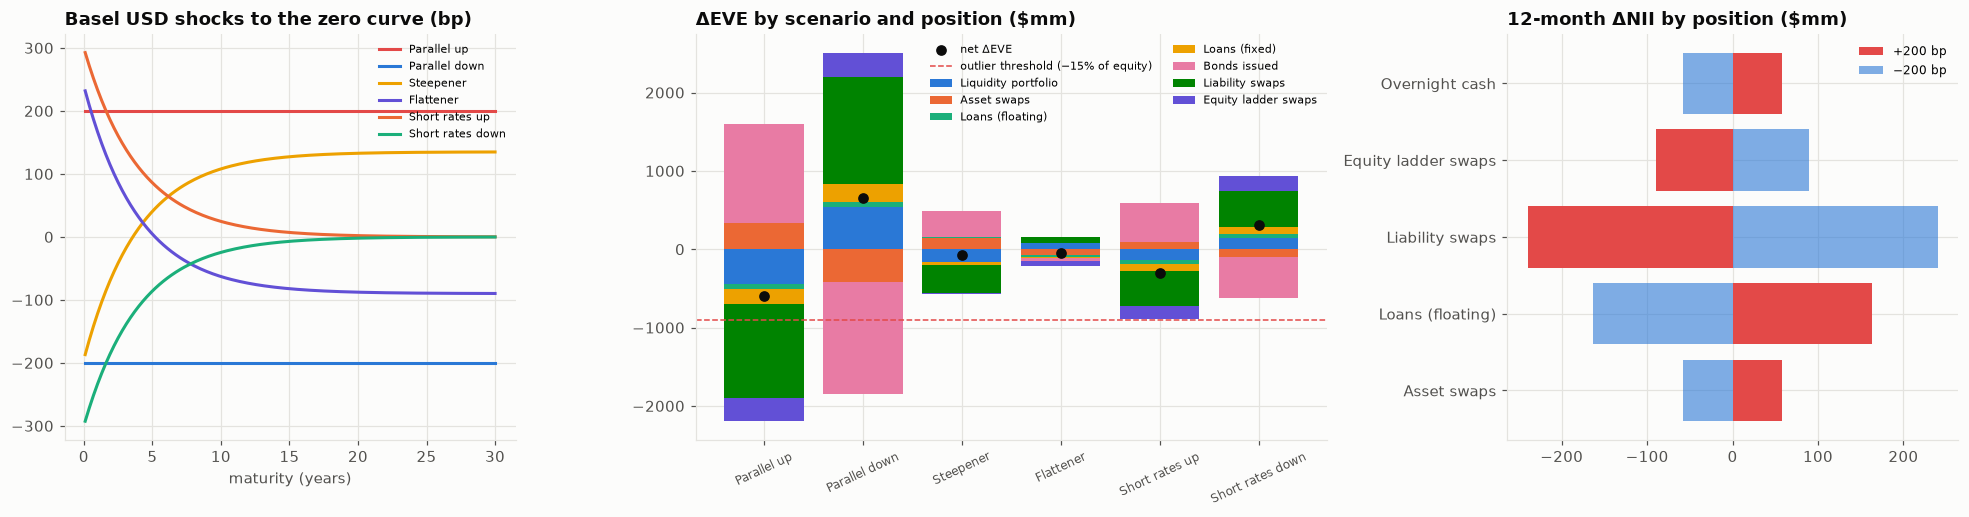

In [11]:
# --- Chart 1: Basel ΔEVE by scenario and contribution, and the shock shapes
fig, axes = plt.subplots(
    1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1.4, 1]}
)
tt = np.linspace(0.1, 30, 200)
for s in SCEN_ORDER:
    axes[0].plot(tt, shock_fn(s)(tt) * 1e4, color=SCEN_COLORS[s], label=s)
axes[0].set_title("Basel USD shocks to the zero curve (bp)")
axes[0].set_xlabel("maturity (years)")
axes[0].legend(fontsize=7)
groups = [
    "Liquidity portfolio",
    "Asset swaps",
    "Loans (floating)",
    "Loans (fixed)",
    "Bonds issued",
    "Liability swaps",
    "Equity ladder swaps",
]
bottom_pos, bottom_neg = np.zeros(len(SCEN_ORDER)), np.zeros(len(SCEN_ORDER))
for g, c in zip(groups, PALETTE + ["#9c9b97"]):
    v = eve.reindex(SCEN_ORDER)[g].to_numpy() * 1e3
    axes[1].bar(
        SCEN_ORDER, np.where(v > 0, v, 0), bottom=bottom_pos, color=c, label=g
    )
    axes[1].bar(SCEN_ORDER, np.where(v < 0, v, 0), bottom=bottom_neg, color=c)
    bottom_pos += np.where(v > 0, v, 0)
    bottom_neg += np.where(v < 0, v, 0)
axes[1].scatter(
    SCEN_ORDER,
    eve.reindex(SCEN_ORDER)["ΔEVE ($bn)"] * 1e3,
    color=INK,
    zorder=3,
    label="net ΔEVE",
)
axes[1].axhline(
    -0.15 * EQUITY_BN * 1e3,
    color=STATUS["red"],
    ls="--",
    lw=1,
    label="outlier threshold (−15% of equity)",
)
axes[1].set_title("ΔEVE by scenario and position ($mm)")
axes[1].tick_params(axis="x", rotation=25, labelsize=8)
axes[1].legend(fontsize=7, ncol=2)
axes[2].barh(
    nii_tab.index[:-1],
    nii_tab["ΔNII +200bp ($mm)"].iloc[:-1],
    color=PALETTE[7],
    label="+200 bp",
)
axes[2].barh(
    nii_tab.index[:-1],
    nii_tab["ΔNII −200bp ($mm)"].iloc[:-1],
    color=PALETTE[0],
    alpha=0.6,
    label="−200 bp",
)
axes[2].set_title("12-month ΔNII by position ($mm)")
axes[2].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_basel_eve_nii")
plt.show()

## 7. Beyond the six shocks: 1-year historical curve moves

The Basel shocks are large and stylised. Overlapping 1-year changes of the Treasury curve over the last ten years (about 2,250 scenarios, applied to today's SOFR curve, with the zero floor) give a distribution of ΔEVE. A PCA of the same changes gives level, slope and curvature factors, and an OLS regression of ΔEVE on the three factor scores shows which shape the balance sheet is exposed to.

In [12]:
# decimal, 1-year changes at the key tenors
yr_changes = (history - history.shift(252)).dropna() / 100
tenors = np.array(history.columns, dtype=float)
# weekly sampling of the overlapping windows
sample = yr_changes.iloc[::5]
sim = []
for _, row in sample.iterrows():
    shift = lambda t, r=row.to_numpy(): np.interp(t, tenors, r)
    sim.append(eve_change(shift, book + ladder).sum())
sim = pd.Series(sim, index=sample.index)
pca = PCA(3).fit(yr_changes.to_numpy())
scores = pca.transform(sample.to_numpy())
Xf = np.column_stack([np.ones(len(scores)), scores])
beta, *_ = np.linalg.lstsq(Xf, sim.to_numpy(), rcond=None)
fitted = Xf @ beta
r2 = 1 - np.sum((sim - fitted) ** 2) / np.sum((sim - sim.mean()) ** 2)
loads = pd.DataFrame(
    pca.components_.T,
    index=[tenor_label(t) for t in tenors],
    columns=["level", "slope", "curvature"],
)
fac = pd.DataFrame(
    {
        "explained variance %": pca.explained_variance_ratio_ * 100,
        "ΔEVE per +1 s.d. of factor ($mm)": (
            beta[1:] * np.sqrt(pca.explained_variance_) * 1e3
        ),
    },
    index=["level", "slope", "curvature"],
)
ear = -np.quantile(sim, 0.01)
print(
    f"{len(sim)} historical 1-year scenarios · ΔEVE 1st pct"
    f" {np.quantile(sim, 0.01) * 1e3:,.0f}mm"
    f" ({np.quantile(sim, 0.01) / EQUITY_BN * 100:.1f}% of equity) · median"
    f" {sim.median() * 1e3:,.0f}mm · factor regression R² {r2:.3f}"
)
fac.round(1)

450 historical 1-year scenarios · ΔEVE 1st pct -901mm (-15.0% of equity) · median -102mm · factor regression R² 0.998


,explained variance %,ΔEVE per +1 s.d. of factor ($mm)
level,90.90,-339.00
slope,6.90,91.60
curvature,1.90,26.90


## 8. The equity-duration frontier

The base policy invests equity in a 1–5-year receive-fixed ladder. The same calculation is repeated for ladders of 0 years (no equity swaps) to 10 years. Each policy gives a pair: **EVE risk**, the worst Basel ΔEVE in % of equity, and **NII risk**, the larger average annual fall in NII over **three years** under +200 or −200 bp, in % of base NII.

A 12-month NII measure cannot tell ladders apart, because none of a ladder's fixed legs beyond one year reprices within the first year; MDBs therefore look at multi-year NII when they set equity duration. Moving along the frontier trades one risk for the other.

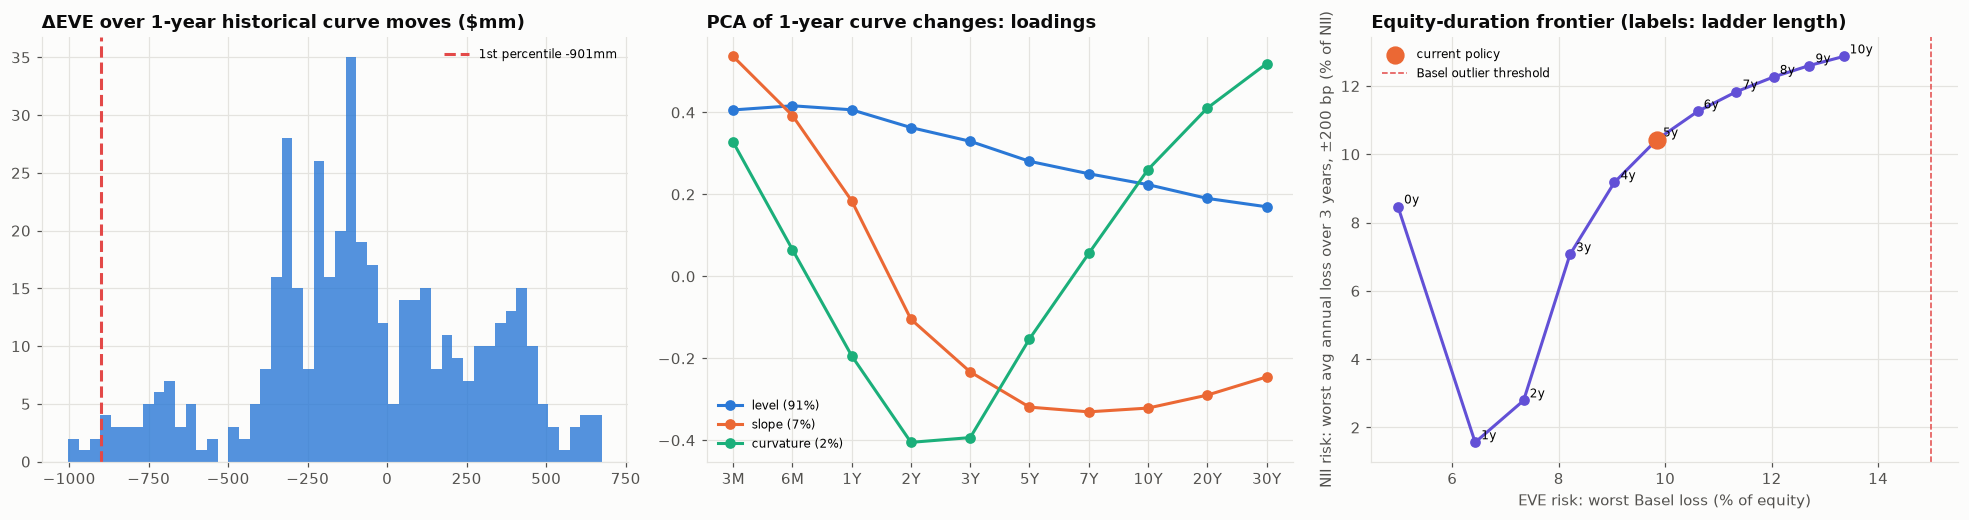

,equity duration (yrs),worst Basel ΔEVE % of equity,ΔNII −200bp % of base NII,3-year avg ΔNII −200bp % of base NII,3-year avg ΔNII +200bp % of base NII,NII risk: worst 3-year avg ΔNII ±200bp %
ladder (years),,,,,,
0,2.67,-4.98,-8.92,-8.47,8.47,-8.47
1,3.40,-6.43,11.21,-1.56,1.56,-1.56
2,3.87,-7.34,11.01,2.79,-2.79,-2.79
3,4.32,-8.21,10.94,7.07,-7.07,-7.07
4,4.76,-9.05,10.89,9.18,-9.18,-9.18
5,5.19,-9.84,10.86,10.43,-10.43,-10.43
6,5.61,-10.61,10.83,11.25,-11.25,-11.25
7,6.01,-11.34,10.80,11.83,-11.83,-11.83
8,6.40,-12.04,10.78,12.27,-12.27,-12.27


In [13]:
frontier = []
for yrs in range(0, 11):
    lad = equity_ladder(base_curve, yrs)
    worst_eve = min(
        eve_change(shock_fn(s), book + lad).sum() for s in SCEN_ORDER
    )
    nb0, _ = nii_parts(book + lad, 0.0)
    _, nd = nii_parts(book + lad, -0.02)
    _, nd3 = nii_parts(book + lad, -0.02, horizon=3.0)
    _, nu3 = nii_parts(book + lad, 0.02, horizon=3.0)
    # equity duration: −ΔEVE for +1bp parallel / equity, in years
    d01 = eve_change(lambda t: 1e-4 + 0 * t, book + lad).sum()
    frontier.append({
        "ladder (years)": yrs,
        "equity duration (yrs)": -d01 / EQUITY_BN / 1e-4,
        "worst Basel ΔEVE % of equity": worst_eve / EQUITY_BN * 100,
        "ΔNII −200bp % of base NII": nd.sum() / nb0.sum() * 100,
        "3-year avg ΔNII −200bp % of base NII": nd3.sum() / nb0.sum() * 100,
        "3-year avg ΔNII +200bp % of base NII": nu3.sum() / nb0.sum() * 100,
    })
frontier = pd.DataFrame(frontier).set_index("ladder (years)")
frontier["NII risk: worst 3-year avg ΔNII ±200bp %"] = frontier[[
    "3-year avg ΔNII −200bp % of base NII",
    "3-year avg ΔNII +200bp % of base NII",
]].min(axis=1)

# --- Chart 2: historical ΔEVE distribution, PCA factors, and the frontier
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].hist(sim * 1e3, bins=50, color=PALETTE[0], alpha=0.8)
axes[0].axvline(
    -ear * 1e3,
    color=STATUS["red"],
    ls="--",
    label=f"1st percentile {-ear * 1e3:,.0f}mm",
)
axes[0].set_title("ΔEVE over 1-year historical curve moves ($mm)")
axes[0].legend(fontsize=8)
for k, c in zip(loads.columns, [PALETTE[0], PALETTE[1], PALETTE[2]]):
    axes[1].plot(
        loads.index,
        loads[k],
        "o-",
        color=c,
        label=f"{k} ({fac.loc[k, 'explained variance %']:.0f}%)",
    )
axes[1].set_title("PCA of 1-year curve changes: loadings")
axes[1].legend(fontsize=8)
ax = axes[2]
ax.plot(
    -frontier["worst Basel ΔEVE % of equity"],
    -frontier["NII risk: worst 3-year avg ΔNII ±200bp %"],
    "o-",
    color=PALETTE[6],
)
for yrs, r in frontier.iterrows():
    ax.annotate(
        f"{yrs}y",
        (
            -r["worst Basel ΔEVE % of equity"],
            -r["NII risk: worst 3-year avg ΔNII ±200bp %"],
        ),
        fontsize=8,
        xytext=(4, 2),
        textcoords="offset points",
    )
b = frontier.loc[EQUITY_LADDER_YEARS]
ax.scatter(
    -b["worst Basel ΔEVE % of equity"],
    -b["NII risk: worst 3-year avg ΔNII ±200bp %"],
    s=120,
    color=PALETTE[1],
    zorder=3,
    label="current policy",
)
ax.axvline(
    15, color=STATUS["red"], ls="--", lw=1, label="Basel outlier threshold"
)
ax.set_xlabel("EVE risk: worst Basel loss (% of equity)")
ax.set_ylabel(
    "NII risk: worst avg annual loss over 3 years, ±200 bp (% of NII)"
)
ax.set_title("Equity-duration frontier (labels: ladder length)")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_historical_pca_frontier")
plt.show()
frontier.round(2)

## 9. Results dashboard

In [14]:
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.16,
    horizontal_spacing=0.1,
    subplot_titles=(
        "ΔEVE under the Basel shocks (% of equity)",
        "12-month ΔNII ($mm)",
        "ΔEVE over historical 1-year curve moves ($mm)",
        "Equity-duration frontier",
    ),
)
v = eve.reindex(SCEN_ORDER)["ΔEVE % of equity"]
dash.add_trace(
    go.Bar(
        x=SCEN_ORDER,
        y=v,
        marker_color=[
            (
                STATUS["red"]
                if x < -15
                else STATUS["amber"] if x < -7.5 else STATUS["green"]
            )
            for x in v
        ],
        text=v.round(1),
        textposition="outside",
        showlegend=False,
    ),
    1,
    1,
)
dash.add_hline(
    y=-15,
    line_dash="dash",
    line_color=STATUS["red"],
    row=1,
    col=1,
    annotation_text="outlier −15%",
)
dash.add_trace(
    go.Bar(
        x=["+200 bp", "−200 bp"],
        y=nii_tab.loc["Total"].to_numpy(),
        marker_color=[PALETTE[7], PALETTE[0]],
        text=nii_tab.loc["Total"].round(0),
        textposition="outside",
        showlegend=False,
    ),
    1,
    2,
)
dash.add_trace(
    go.Histogram(
        x=sim * 1e3, nbinsx=50, marker_color=PALETTE[0], showlegend=False
    ),
    2,
    1,
)
dash.add_trace(
    go.Scatter(
        x=-frontier["worst Basel ΔEVE % of equity"],
        y=-frontier["NII risk: worst 3-year avg ΔNII ±200bp %"],
        mode="lines+markers+text",
        text=[f"{y}y" for y in frontier.index],
        textposition="top center",
        line=dict(color=PALETTE[6]),
        showlegend=False,
    ),
    2,
    2,
)
dash.add_trace(
    go.Scatter(
        x=[-b["worst Basel ΔEVE % of equity"]],
        y=[-b["NII risk: worst 3-year avg ΔNII ±200bp %"]],
        mode="markers",
        marker=dict(size=16, color=PALETTE[1]),
        name="current policy",
    ),
    2,
    2,
)
dash.update_xaxes(title_text="EVE risk (% of equity)", row=2, col=2)
dash.update_yaxes(title_text="NII risk, 3-year avg (% of NII)", row=2, col=2)
dash.update_layout(
    height=950,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    margin=dict(t=130),
    legend=dict(orientation="h", y=-0.08),
    title=dict(
        x=0.01,
        text=(
            "<b>IRRBB · stylised MDB balance sheet, SOFR curve of"
            f" {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>Worst Basel ΔEVE"
            f" {eve.loc[worst, 'ΔEVE % of equity']:.1f}% of equity ({worst}) ·"
            f" ΔNII −200bp {nii_tab.loc['Total', 'ΔNII −200bp ($mm)']:,.0f}mm"
            " · equity duration"
            f" {frontier.loc[EQUITY_LADDER_YEARS, 'equity duration (yrs)']:.1f}y"
            f" · historical 1y ΔEVE 1st pct {-ear * 1e3:,.0f}mm</span>"
        ),
    ),
)
save_dashboard(dash, "dashboard")
eve.to_csv(OUT_DIR / "basel_eve.csv")
nii_tab.to_csv(OUT_DIR / "nii_sensitivity.csv")
frontier.to_csv(OUT_DIR / "equity_duration_frontier.csv")
sim.rename("ΔEVE $bn").to_csv(OUT_DIR / "historical_eve_scenarios.csv")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

A $36bn stylised MDB balance sheet (equity $6bn) on the SOFR curve of 19 October 2026:

**The Basel outlier test passes with room.** The worst standardised shock is a 200 bp parallel rise: ΔEVE −$591mm, **−9.8% of equity** against the 15% threshold. The six scenarios line up almost exactly with equity duration (5.2 years × 2% ≈ 10%): steepener and flattener cost about 1%, short-rate shocks about 5%. The large gross numbers cancel. The fixed-rate bonds gain $1.27bn when rates rise and their swaps lose $1.20bn; the liquidity portfolio loses $441mm and its asset swaps recover $339mm. What is left is the duration of equity, which is the policy choice.

**History is harsher than the Basel set.** Across 450 overlapping 1-year curve changes since 2016, the 1st percentile of ΔEVE is −$901mm (**−15% of equity**). The worst year ended in October 2022 (−$1.0bn), when the whole curve rose about 4 points. The most favourable ended in April 2020 (+$675mm). Basel's 200 bp parallel shock understates a 1-in-100-year move in the post-2016 sample. That is why supervisors also expect internal historical and hypothetical scenarios. Three PCA factors explain the risk almost completely (R² 0.998). Level carries 91% of curve variance and −$339mm per standard deviation; slope and curvature matter at the margin and partly offset it.

- **12-month NII is small and slightly liability-sensitive.** Base NII is $469mm. +200 bp lowers it by $51mm (−11%), because floating funding (the swapped bonds plus the pay-SOFR legs of the equity ladder) exceeds floating assets.

**The frontier shows the base policy is over-hedged.** Even with no equity swaps, equity already has a duration of 2.7 years. The fixed-rate loans and the unswapped 20% of the liquidity portfolio are effectively funded by equity. Laddering all $6bn of equity on top pushes equity duration to 5.2 years. A 1-year ladder minimises 3-year NII risk (−1.6% of NII, against −8.5% with no swaps and −10.4% for the 5-year ladder) at a cost of 6.4% of equity in EVE terms. Every ladder longer than about 2 years raises both EVE risk and NII risk, so those ladders are dominated. The lesson for an equity-duration policy is to size the ladder to the equity that is still floating, not to the whole equity. That is one reason MDBs set the target as a duration range rather than as a fixed ladder.

- **12-month ΔNII cannot choose between ladders.** All ladders of 1 year or more show the same ±11% (the fixed legs do not reprice inside one year); only the 3-year view separates them. This is why the frontier uses multi-year NII.

**Limitations**

- The balance sheet is stylised: loans, funding and equity sizes are illustrative; only the liquidity portfolio holds real bonds.
- One SOFR curve built from Treasuries plus a constant swap spread; there is no basis risk between SOFR, Treasuries and the bond's own curve, and no credit-spread risk in ΔEVE.
- NII assumes a constant balance sheet with instant pass-through; loan prepayment, new lending and the zero floor on loan spreads are not modelled.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2016). *Interest rate risk in the banking book* (BCBS 368). Bank for International Settlements. https://www.bis.org/bcbs/publ/d368.htm
- English, W. B., Van den Heuvel, S. J., & Zakrajšek, E. (2018). Interest rate risk and bank equity valuations. *Journal of Monetary Economics, 98*, 80–97. https://doi.org/10.1016/j.jmoneco.2018.04.010
- Drechsler, I., Savov, A., & Schnabl, P. (2021). Banking on deposits: Maturity transformation without interest rate risk. *The Journal of Finance, 76*(3), 1091–1143. https://doi.org/10.1111/jofi.13013
- Litterman, R., & Scheinkman, J. (1991). Common factors affecting bond returns. *The Journal of Fixed Income, 1*(1), 54–61. https://doi.org/10.3905/jfi.1991.692347

### Machine learning and deep learning

- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202
- Markowitz, H. (1952). Portfolio selection. *The Journal of Finance, 7*(1), 77–91. https://doi.org/10.1111/j.1540-6261.1952.tb01525.x